# Part 3 — Syntax vs. Semantics in Qwen3-4B-Base with BLiMP

**Research question:** How reliably does Qwen3-4B-Base prefer acceptable English sentences over minimally different unacceptable alternatives, and how does performance vary across linguistic phenomena?

This notebook uses the published **BLiMP (Benchmark of Linguistic Minimal Pairs)** rather than relying only on hand-written examples. BLiMP contains 67 paradigms of 1,000 minimal pairs each. For a Kaggle-friendly but substantial analysis, this notebook samples **250 pairs from each of eight paradigms (2,000 pairs total)**.

### Paradigms
- Regular plural subject–verb agreement
- Determiner–noun agreement
- Anaphor gender agreement
- Argument structure / dropped arguments
- Tough vs. raising constructions
- Negative polarity item licensing
- Superlative quantifiers
- Wh-island constraints

The dataset's own `field` metadata (`morphology`, `syntax`, `syntax-semantics`, or `semantics`) is retained and used for analysis; paradigms are not manually relabeled into an oversimplified syntax/semantics split.

### Scoring
For each acceptable (`sentence_good`) and unacceptable (`sentence_bad`) pair, the frozen causal LM scores conditional token log-probabilities. We report (1) the sum of token log-probabilities as the primary whole-sentence comparison and (2) mean token log-probability as a length-normalized sensitivity analysis. Pairwise accuracy is the fraction of pairs where the acceptable sentence scores higher.

**No ablation or fine-tuning is performed.** This is an intact-model linguistic evaluation.

### Kaggle setup
Enable **Internet** and a **GPU accelerator**, then run cells from the top. The 4B model requires significant GPU memory. Results are checkpointed after each completed paradigm.

### Dataset citation
Warstadt et al. (2020), *BLiMP: The Benchmark of Linguistic Minimal Pairs for English*, TACL 8, 377–392, DOI: `10.1162/tacl_a_00321`. BLiMP is available at [Hugging Face](https://huggingface.co/datasets/nyu-mll/blimp), [official repository](https://github.com/alexwarstadt/blimp), and [ACL Anthology](https://aclanthology.org/2020.tacl-1.25/).

## 1. Environment and configuration

Kaggle often already has compatible libraries. If imports fail or Transformers is older than 4.51, uncomment the install command, run it, restart the session if prompted, and run from the top.

In [1]:
# Optional if required (does not reinstall torch):
# %pip install -q "transformers>=4.51.0,<5.0" "datasets>=4.0.0,<5.0" "accelerate>=1.0.0" pandas numpy matplotlib tqdm

import os, gc, json, random, platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, transformers, datasets
from datasets import load_dataset
from tqdm.auto import tqdm
from transformers import AutoTokenizer, AutoModelForCausalLM

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
MODEL_ID = "Qwen/Qwen3-4B-Base"
DATASET_ID = "nyu-mll/blimp"
PAIRS_PER_PARADIGM = 250          # 8 x 250 = 2,000 minimal pairs
MAX_SEQUENCE_TOKENS = 160         # pairs are excluded, not truncated
PAIR_BATCH_SIZE = 8               # adaptive split handles CUDA OOM
BOOTSTRAP_REPS = 1000
PARADIGMS = [
    ("regular_plural_subject_verb_agreement_1", "Subject–verb agreement"),
    ("determiner_noun_agreement_1", "Determiner–noun agreement"),
    ("anaphor_gender_agreement", "Anaphor gender agreement"),
    ("drop_argument", "Argument structure"),
    ("tough_vs_raising_1", "Tough vs. raising"),
    ("npi_present_1", "Negative polarity item licensing"),
    ("superlative_quantifiers_1", "Superlative quantifiers"),
    ("wh_island", "Wh-island constraints"),
]
OUT_DIR = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path(".")
OUT_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_PATH = OUT_DIR / "qwen3_blimp_results.csv"
DETAILS_PATH = OUT_DIR / "qwen3_blimp_pair_scores.csv"
SUMMARY_PATH = OUT_DIR / "qwen3_blimp_summary.csv"
CONFIG_PATH = OUT_DIR / "qwen3_blimp_config.json"
print({"python":platform.python_version(), "torch":torch.__version__, "transformers":transformers.__version__,
       "datasets":datasets.__version__, "cuda":torch.cuda.is_available(), "out_dir":str(OUT_DIR)})
if torch.cuda.is_available(): print("GPUs:", [torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())])

{'python': '3.13.15', 'torch': '2.11.0+cu128', 'transformers': '5.16.1', 'datasets': '4.8.5', 'cuda': True, 'out_dir': '/kaggle/working'}
GPUs: ['Tesla T4', 'Tesla T4']


## 2. Load the frozen model

FP16 is used on Kaggle T4 GPUs; BF16 is used only on supported newer GPUs. The model is in evaluation mode and its parameters are never updated.

In [2]:
if not torch.cuda.is_available():
    raise RuntimeError("No CUDA GPU found. Enable a GPU and Internet in Kaggle Notebook Settings, then restart and run from the top.")
try:
    tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, use_fast=True)
    cap_major = torch.cuda.get_device_capability(0)[0]
    dtype = torch.bfloat16 if cap_major >= 8 and torch.cuda.is_bf16_supported() else torch.float16
    model = AutoModelForCausalLM.from_pretrained(
        MODEL_ID, dtype=dtype, device_map="auto", low_cpu_mem_usage=True,
        attn_implementation="sdpa", use_safetensors=True
    )
    model.eval(); model.config.use_cache = False
except Exception as exc:
    raise RuntimeError(f"Model load failed. Check Kaggle Internet/GPU memory. {type(exc).__name__}: {exc}") from exc
INPUT_DEVICE = model.get_input_embeddings().weight.device
BOS_ID = tokenizer.bos_token_id
PAD_ID = tokenizer.pad_token_id if tokenizer.pad_token_id is not None else tokenizer.eos_token_id
print({"model":MODEL_ID, "dtype":str(dtype), "input_device":str(INPUT_DEVICE), "bos_id":BOS_ID, "pad_id":PAD_ID,
       "device_map":getattr(model,"hf_device_map",None)})

config.json:   0%|          | 0.00/727 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.68k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/138 [00:00<?, ?B/s]

{'model': 'Qwen/Qwen3-4B-Base', 'dtype': 'torch.float16', 'input_device': 'cuda:0', 'bos_id': None, 'pad_id': 151643, 'device_map': {'model.embed_tokens': 0, 'lm_head': 0, 'model.layers.0': 0, 'model.layers.1': 0, 'model.layers.2': 0, 'model.layers.3': 0, 'model.layers.4': 0, 'model.layers.5': 0, 'model.layers.6': 0, 'model.layers.7': 0, 'model.layers.8': 0, 'model.layers.9': 0, 'model.layers.10': 0, 'model.layers.11': 0, 'model.layers.12': 0, 'model.layers.13': 0, 'model.layers.14': 0, 'model.layers.15': 0, 'model.layers.16': 1, 'model.layers.17': 1, 'model.layers.18': 1, 'model.layers.19': 1, 'model.layers.20': 1, 'model.layers.21': 1, 'model.layers.22': 1, 'model.layers.23': 1, 'model.layers.24': 1, 'model.layers.25': 1, 'model.layers.26': 1, 'model.layers.27': 1, 'model.layers.28': 1, 'model.layers.29': 1, 'model.layers.30': 1, 'model.layers.31': 1, 'model.layers.32': 1, 'model.layers.33': 1, 'model.layers.34': 1, 'model.layers.35': 1, 'model.norm': 1, 'model.rotary_emb': 1}}


## 3. Load and sample eight BLiMP paradigms

Each configuration contains 1,000 pairs. We tokenize the full sentences, exclude pairs longer than the maximum instead of truncating away potentially decisive material, then take a deterministic random sample of 250 eligible pairs per paradigm.

In [3]:
def encode_sentence(sentence):
    ids = tokenizer(str(sentence), add_special_tokens=False)["input_ids"]
    if BOS_ID is not None:
        ids = [int(BOS_ID)] + [int(x) for x in ids]
    else:
        ids = [int(x) for x in ids]
    return ids

def load_paradigm(config_name, display_name):
    try:
        ds = load_dataset(DATASET_ID, config_name, split="train")
    except Exception as exc:
        raise RuntimeError(f"Could not load BLiMP config {config_name!r}. Check Kaggle Internet. "
                           f"Original: {type(exc).__name__}: {exc}") from exc
    eligible=[]; too_long=0
    for row in ds:
        good=str(row["sentence_good"]).strip(); bad=str(row["sentence_bad"]).strip()
        good_ids=encode_sentence(good); bad_ids=encode_sentence(bad)
        if len(good_ids)>MAX_SEQUENCE_TOKENS or len(bad_ids)>MAX_SEQUENCE_TOKENS:
            too_long += 1; continue
        eligible.append({
            "config":config_name, "paradigm":display_name, "field":str(row.get("field","unknown")),
            "linguistics_term":str(row.get("linguistics_term","unknown")), "pair_id":int(row.get("pair_id",len(eligible))),
            "sentence_good":good, "sentence_bad":bad, "good_ids":good_ids, "bad_ids":bad_ids,
            "simple_LM_method":bool(row.get("simple_LM_method",False)),
            "lexically_identical":bool(row.get("lexically_identical",False)),
        })
    if len(eligible)<PAIRS_PER_PARADIGM:
        raise RuntimeError(f"{config_name}: only {len(eligible)} eligible pairs; need {PAIRS_PER_PARADIGM}. "
                           "Lower PAIRS_PER_PARADIGM or increase MAX_SEQUENCE_TOKENS.")
    rng=np.random.default_rng(SEED + sum(ord(ch) for ch in config_name))
    chosen=rng.choice(len(eligible), size=PAIRS_PER_PARADIGM, replace=False)
    selected=[eligible[int(i)] for i in chosen]
    info={"config":config_name, "paradigm":display_name, "original_pairs":len(ds),
          "eligible_pairs":len(eligible), "excluded_too_long":too_long, "sampled_pairs":len(selected),
          "field":selected[0]["field"], "linguistics_term":selected[0]["linguistics_term"]}
    return selected,info

sampled_pairs=[]; dataset_info=[]
for config_name, display_name in PARADIGMS:
    selected,info=load_paradigm(config_name,display_name)
    sampled_pairs.extend(selected); dataset_info.append(info)
dataset_info_df=pd.DataFrame(dataset_info)
display(dataset_info_df)
print("Total pairs:",len(sampled_pairs),"; fields:",sorted(set(r["field"] for r in sampled_pairs)))
print("Example acceptable:",sampled_pairs[0]["sentence_good"])
print("Example unacceptable:",sampled_pairs[0]["sentence_bad"])

README.md:   0%|          | 0.00/58.6k [00:00<?, ?B/s]

regular_plural_subject_verb_agreement_1/(…): reconstructing file:   0%|          |  0.00B / 49.5kB            

regular_plural_subject_verb_agreement_1/(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/1000 [00:00<?, ? examples/s]

determiner_noun_agreement_1/train-00000-(…): reconstructing file:   0%|          |  0.00B / 49.9kB            

...

wh_island/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 52.8kB            

wh_island/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/1000 [00:00<?, ? examples/s]

,config,paradigm,original_pairs,eligible_pairs,excluded_too_long,sampled_pairs,field,linguistics_term
0,regular_plural_subject_verb_agreement_1,Subject–verb agreement,1000,1000,0,250,morphology,subject_verb_agreement
1,determiner_noun_agreement_1,Determiner–noun agreement,1000,1000,0,250,morphology,determiner_noun_agreement
2,anaphor_gender_agreement,Anaphor gender agreement,1000,1000,0,250,morphology,anaphor_agreement
3,drop_argument,Argument structure,1000,1000,0,250,syntax,argument_structure
4,tough_vs_raising_1,Tough vs. raising,1000,1000,0,250,syntax_semantics,control_raising
5,npi_present_1,Negative polarity item licensing,1000,1000,0,250,semantics,npi_licensing
6,superlative_quantifiers_1,Superlative quantifiers,1000,1000,0,250,semantics,quantifiers
7,wh_island,Wh-island constraints,1000,1000,0,250,syntax,island_effects


Total pairs: 2000 ; fields: ['morphology', 'semantics', 'syntax', 'syntax_semantics']
Example acceptable: Many teenagers forget that boy.
Example unacceptable: Many teenagers forgets that boy.


## 4. Reproducibility and checkpoint settings

In [4]:
run_config={"model_id":MODEL_ID,"dataset_id":DATASET_ID,"paradigms":PARADIGMS,
            "pairs_per_paradigm":PAIRS_PER_PARADIGM,"max_sequence_tokens":MAX_SEQUENCE_TOKENS,
            "pair_batch_size":PAIR_BATCH_SIZE,"seed":SEED,
            "transformers_version":transformers.__version__,"datasets_version":datasets.__version__}
if CONFIG_PATH.exists():
    try: old_config=json.loads(CONFIG_PATH.read_text())
    except Exception: old_config=None
    if old_config != run_config:
        print("Experiment configuration changed; clearing old checkpoints to avoid mixing results.")
        for path in [RESULTS_PATH,DETAILS_PATH,SUMMARY_PATH]:
            if path.exists(): path.unlink()
CONFIG_PATH.write_text(json.dumps(run_config,indent=2))
display(pd.DataFrame([{"pairs":len(sampled_pairs),"paradigms":len(PARADIGMS),"primary":"summed sentence log-likelihood",
                       "sensitivity check":"mean token log-likelihood","retraining":"none","ablation":"none"}]))

,pairs,paradigms,primary,sensitivity check,retraining,ablation
0,2000,8,summed sentence log-likelihood,mean token log-likelihood,none,none


## 5. Score pairs with the language model

We calculate each content token probability conditioned on its preceding tokens. The primary score is the sum over tokens; a mean-per-token score is included as a length-normalized sensitivity analysis. Both scores compare the acceptable and unacceptable alternatives within each pair.

In [5]:
def score_pairs_batch(pairs):
    seqs=[]
    for row in pairs: seqs.extend([row["good_ids"],row["bad_ids"]])
    max_len=max(map(len,seqs))
    ids=torch.full((len(seqs),max_len),int(PAD_ID),dtype=torch.long)
    mask=torch.zeros((len(seqs),max_len),dtype=torch.long)
    for i,seq in enumerate(seqs):
        ids[i,:len(seq)]=torch.tensor(seq,dtype=torch.long); mask[i,:len(seq)]=1
    ids=ids.to(INPUT_DEVICE); mask=mask.to(INPUT_DEVICE)
    try:
        with torch.inference_mode():
            out=model(input_ids=ids,attention_mask=mask,use_cache=False)
            logits=out.logits[:,:-1,:].float()
            targets=ids[:,1:]
            target_mask=mask[:,1:].to(logits.device)
            selected=logits.gather(-1,targets.unsqueeze(-1)).squeeze(-1)
            token_lp=selected-torch.logsumexp(logits,dim=-1)
            token_lp=token_lp*target_mask
            sums=token_lp.sum(1)
            counts=target_mask.sum(1).clamp_min(1)
            means=sums/counts
            sums=sums.cpu().numpy(); means=means.cpu().numpy(); counts=counts.cpu().numpy()
    finally:
        del ids,mask
        if torch.cuda.is_available(): torch.cuda.empty_cache()
    rows=[]
    for i,pair in enumerate(pairs):
        gs,bs=float(sums[2*i]),float(sums[2*i+1]); gm,bm=float(means[2*i]),float(means[2*i+1])
        rows.append({"config":pair["config"],"paradigm":pair["paradigm"],"field":pair["field"],
          "linguistics_term":pair["linguistics_term"],"pair_id":pair["pair_id"],
          "sentence_good":pair["sentence_good"],"sentence_bad":pair["sentence_bad"],
          "simple_LM_method":pair["simple_LM_method"],"lexically_identical":pair["lexically_identical"],
          "good_token_count":int(counts[2*i]),"bad_token_count":int(counts[2*i+1]),
          "good_sum_logprob":gs,"bad_sum_logprob":bs,"sum_margin_good_minus_bad":gs-bs,
          "sum_preferred_good":bool(gs>bs),"good_mean_token_logprob":gm,"bad_mean_token_logprob":bm,
          "mean_margin_good_minus_bad":gm-bm,"mean_preferred_good":bool(gm>bm)})
    return rows

def score_pairs_adaptive(pairs):
    try:
        return score_pairs_batch(pairs)
    except torch.cuda.OutOfMemoryError:
        if torch.cuda.is_available(): torch.cuda.empty_cache()
        if len(pairs)<=1: raise
        mid=len(pairs)//2
        return score_pairs_adaptive(pairs[:mid])+score_pairs_adaptive(pairs[mid:])

# Smoke-test two pairs before a long run. These are not included as extra results.
display(pd.DataFrame(score_pairs_adaptive(sampled_pairs[:2]))[["paradigm","good_token_count","bad_token_count",
  "sum_margin_good_minus_bad","mean_margin_good_minus_bad"]])

,paradigm,good_token_count,bad_token_count,sum_margin_good_minus_bad,mean_margin_good_minus_bad
0,Subject–verb agreement,5,6,0.834686,-1.292710
1,Subject–verb agreement,7,7,3.470978,0.495854


## 6. Run benchmark with paradigm-level checkpoints

Completed paradigms are saved to CSV. If the Kaggle session is interrupted, rerun this cell; it skips paradigms that already have detailed score rows. Do not change configurations mid-run unless the checkpoint files are cleared.

In [6]:
results_rows=pd.read_csv(RESULTS_PATH).to_dict("records") if RESULTS_PATH.exists() else []
details_df=pd.read_csv(DETAILS_PATH) if DETAILS_PATH.exists() else pd.DataFrame()
completed=set(details_df["config"].astype(str).unique()) if not details_df.empty and "config" in details_df else set()
for cfg,disp in PARADIGMS:
    if cfg in completed:
        print("Skipping completed:",cfg); continue
    current=[r for r in sampled_pairs if r["config"]==cfg]
    scored=[]
    for start in tqdm(range(0,len(current),PAIR_BATCH_SIZE),desc=disp):
        try: scored.extend(score_pairs_adaptive(current[start:start+PAIR_BATCH_SIZE]))
        except Exception as exc:
            raise RuntimeError(f"Scoring failed for {cfg} at pair {start}. Reduce PAIR_BATCH_SIZE. "
                               f"{type(exc).__name__}: {exc}") from exc
    part=pd.DataFrame(scored)
    row={"config":cfg,"paradigm":disp,"field":part["field"].mode().iloc[0],
         "linguistics_term":part["linguistics_term"].mode().iloc[0],"n_pairs":len(part),
         "sum_pairwise_accuracy":part["sum_preferred_good"].mean(),
         "sum_mean_margin":part["sum_margin_good_minus_bad"].mean(),
         "mean_token_pairwise_accuracy":part["mean_preferred_good"].mean(),
         "mean_token_margin":part["mean_margin_good_minus_bad"].mean(),
         "mean_good_tokens":part["good_token_count"].mean(),"mean_bad_tokens":part["bad_token_count"].mean(),
         "simple_LM_method_fraction":part["simple_LM_method"].mean(),
         "lexically_identical_fraction":part["lexically_identical"].mean()}
    results_rows.append(row)
    details_df=part.copy() if details_df.empty else pd.concat([details_df,part],ignore_index=True)
    pd.DataFrame(results_rows).to_csv(RESULTS_PATH,index=False)
    details_df.to_csv(DETAILS_PATH,index=False)
    completed.add(cfg)
    print(row)
results_df=pd.DataFrame(results_rows)
display(results_df)
print("Saved results:",RESULTS_PATH,"\nPair details:",DETAILS_PATH)

Subject–verb agreement:   0%|          | 0/32 [00:00<?, ?it/s]

{'config': 'regular_plural_subject_verb_agreement_1', 'paradigm': 'Subject–verb agreement', 'field': 'morphology', 'linguistics_term': 'subject_verb_agreement', 'n_pairs': 250, 'sum_pairwise_accuracy': np.float64(0.888), 'sum_mean_margin': np.float64(3.7295627059936525), 'mean_token_pairwise_accuracy': np.float64(0.848), 'mean_token_margin': np.float64(0.6900984840393066), 'mean_good_tokens': np.float64(5.872), 'mean_bad_tokens': np.float64(5.864), 'simple_LM_method_fraction': np.float64(1.0), 'lexically_identical_fraction': np.float64(0.0)}


Determiner–noun agreement:   0%|          | 0/32 [00:00<?, ?it/s]

{'config': 'determiner_noun_agreement_1', 'paradigm': 'Determiner–noun agreement', 'field': 'morphology', 'linguistics_term': 'determiner_noun_agreement', 'n_pairs': 250, 'sum_pairwise_accuracy': np.float64(0.988), 'sum_mean_margin': np.float64(5.221847694396972), 'mean_token_pairwise_accuracy': np.float64(0.956), 'mean_token_margin': np.float64(0.8424925909042359), 'mean_good_tokens': np.float64(6.392), 'mean_bad_tokens': np.float64(6.4), 'simple_LM_method_fraction': np.float64(1.0), 'lexically_identical_fraction': np.float64(1.0)}


Anaphor gender agreement:   0%|          | 0/32 [00:00<?, ?it/s]

...

{'config': 'superlative_quantifiers_1', 'paradigm': 'Superlative quantifiers', 'field': 'semantics', 'linguistics_term': 'quantifiers', 'n_pairs': 250, 'sum_pairwise_accuracy': np.float64(0.816), 'sum_mean_margin': np.float64(2.022758331298828), 'mean_token_pairwise_accuracy': np.float64(0.816), 'mean_token_margin': np.float64(0.24495006370544434), 'mean_good_tokens': np.float64(8.22), 'mean_bad_tokens': np.float64(8.22), 'simple_LM_method_fraction': np.float64(1.0), 'lexically_identical_fraction': np.float64(0.0)}


Wh-island constraints:   0%|          | 0/32 [00:00<?, ?it/s]

{'config': 'wh_island', 'paradigm': 'Wh-island constraints', 'field': 'syntax', 'linguistics_term': 'island_effects', 'n_pairs': 250, 'sum_pairwise_accuracy': np.float64(0.804), 'sum_mean_margin': np.float64(2.8558952178955077), 'mean_token_pairwise_accuracy': np.float64(0.804), 'mean_token_margin': np.float64(0.3539508590698242), 'mean_good_tokens': np.float64(8.336), 'mean_bad_tokens': np.float64(8.336), 'simple_LM_method_fraction': np.float64(1.0), 'lexically_identical_fraction': np.float64(0.0)}


,config,paradigm,field,linguistics_term,n_pairs,sum_pairwise_accuracy,sum_mean_margin,mean_token_pairwise_accuracy,mean_token_margin,mean_good_tokens,mean_bad_tokens,simple_LM_method_fraction,lexically_identical_fraction
0,regular_plural_subject_verb_agreement_1,Subject–verb agreement,morphology,subject_verb_agreement,250,0.888,3.729563,0.848,0.690098,5.872,5.864,1.0,0.0
1,determiner_noun_agreement_1,Determiner–noun agreement,morphology,determiner_noun_agreement,250,0.988,5.221848,0.956,0.842493,6.392,6.400,1.0,1.0
2,anaphor_gender_agreement,Anaphor gender agreement,morphology,anaphor_agreement,250,0.980,4.327438,0.980,0.904305,5.000,5.000,1.0,0.0
3,drop_argument,Argument structure,syntax,argument_structure,250,0.744,3.380972,0.544,0.228394,4.612,4.976,1.0,0.0
4,tough_vs_raising_1,Tough vs. raising,syntax_semantics,control_raising,250,0.716,3.133547,0.764,0.445116,7.892,7.824,1.0,0.0
5,npi_present_1,Negative polarity item licensing,semantics,npi_licensing,250,0.616,1.113898,0.616,0.176956,7.156,7.156,1.0,0.0
6,superlative_quantifiers_1,Superlative quantifiers,semantics,quantifiers,250,0.816,2.022758,0.816,0.244950,8.220,8.220,1.0,0.0
7,wh_island,Wh-island constraints,syntax,island_effects,250,0.804,2.855895,0.804,0.353951,8.336,8.336,1.0,0.0


Saved results: /kaggle/working/qwen3_blimp_results.csv 
Pair details: /kaggle/working/qwen3_blimp_pair_scores.csv


## 7. Performance by paradigm and BLiMP field

In [7]:
results_df=pd.read_csv(RESULTS_PATH)
details_df=pd.read_csv(DETAILS_PATH)
display(results_df.sort_values("sum_pairwise_accuracy",ascending=False)[[
    "paradigm","field","linguistics_term","n_pairs","sum_pairwise_accuracy",
    "mean_token_pairwise_accuracy","sum_mean_margin","mean_token_margin","mean_good_tokens","mean_bad_tokens"
]].round(4))
field_summary=(details_df.groupby("field",dropna=False).agg(
    n_pairs=("sum_preferred_good","size"),sum_pairwise_accuracy=("sum_preferred_good","mean"),
    mean_token_pairwise_accuracy=("mean_preferred_good","mean"),
    mean_sum_margin=("sum_margin_good_minus_bad","mean"),mean_token_margin=("mean_margin_good_minus_bad","mean"),
    paradigms=("config","nunique")).reset_index().sort_values("sum_pairwise_accuracy",ascending=False))
display(field_summary.round(4))
results_df.to_csv(SUMMARY_PATH,index=False)
field_summary.to_csv(OUT_DIR/"qwen3_blimp_field_summary.csv",index=False)

,paradigm,field,linguistics_term,n_pairs,sum_pairwise_accuracy,mean_token_pairwise_accuracy,sum_mean_margin,mean_token_margin,mean_good_tokens,mean_bad_tokens
1,Determiner–noun agreement,morphology,determiner_noun_agreement,250,0.988,0.956,5.2218,0.8425,6.392,6.400
2,Anaphor gender agreement,morphology,anaphor_agreement,250,0.980,0.980,4.3274,0.9043,5.000,5.000
0,Subject–verb agreement,morphology,subject_verb_agreement,250,0.888,0.848,3.7296,0.6901,5.872,5.864
6,Superlative quantifiers,semantics,quantifiers,250,0.816,0.816,2.0228,0.2450,8.220,8.220
7,Wh-island constraints,syntax,island_effects,250,0.804,0.804,2.8559,0.3540,8.336,8.336
3,Argument structure,syntax,argument_structure,250,0.744,0.544,3.3810,0.2284,4.612,4.976
4,Tough vs. raising,syntax_semantics,control_raising,250,0.716,0.764,3.1335,0.4451,7.892,7.824
5,Negative polarity item licensing,semantics,npi_licensing,250,0.616,0.616,1.1139,0.1770,7.156,7.156


,field,n_pairs,sum_pairwise_accuracy,mean_token_pairwise_accuracy,mean_sum_margin,mean_token_margin,paradigms
0,morphology,750,0.952,0.928,4.4263,0.8123,3
2,syntax,500,0.774,0.674,3.1184,0.2912,2
1,semantics,500,0.716,0.716,1.5683,0.2110,2
3,syntax_semantics,250,0.716,0.764,3.1335,0.4451,1


## 8. Bootstrap confidence intervals

The overall interval resamples examples **within each paradigm** and averages paradigm accuracy, so each of the eight selected paradigms receives equal weight. Per-paradigm intervals resample pairs within each configuration.

In [8]:
rng=np.random.default_rng(SEED)
by_config={cfg:sub.reset_index(drop=True) for cfg,sub in details_df.groupby("config")}
overall_sum_draws=np.zeros(BOOTSTRAP_REPS,dtype=np.float32)
overall_mean_draws=np.zeros(BOOTSTRAP_REPS,dtype=np.float32)
for cfg,sub in by_config.items():
    sw=sub["sum_preferred_good"].astype(float).to_numpy()
    mw=sub["mean_preferred_good"].astype(float).to_numpy()
    for b in range(BOOTSTRAP_REPS):
        idx=rng.integers(0,len(sub),size=len(sub))
        overall_sum_draws[b]+=sw[idx].mean()/len(by_config)
        overall_mean_draws[b]+=mw[idx].mean()/len(by_config)
summary_ci=pd.DataFrame([
 {"metric":"Summed sentence log-likelihood accuracy (primary)","accuracy":details_df.groupby("config")["sum_preferred_good"].mean().mean(),
  "ci95_low":np.quantile(overall_sum_draws,.025),"ci95_high":np.quantile(overall_sum_draws,.975),"n_pairs":len(details_df)},
 {"metric":"Mean token log-likelihood accuracy (sensitivity)","accuracy":details_df.groupby("config")["mean_preferred_good"].mean().mean(),
  "ci95_low":np.quantile(overall_mean_draws,.025),"ci95_high":np.quantile(overall_mean_draws,.975),"n_pairs":len(details_df)}])
display(summary_ci.round(4)); summary_ci.to_csv(OUT_DIR/"qwen3_blimp_overall_ci.csv",index=False)
ci_rows=[]
for cfg,sub in by_config.items():
    win=sub["sum_preferred_good"].astype(float).to_numpy()
    draws=np.array([win[rng.integers(0,len(win),size=len(win))].mean() for _ in range(BOOTSTRAP_REPS)])
    row=results_df[results_df["config"]==cfg].iloc[0]
    ci_rows.append({"config":cfg,"paradigm":row["paradigm"],"n_pairs":len(win),"accuracy":win.mean(),
                    "ci95_low":np.quantile(draws,.025),"ci95_high":np.quantile(draws,.975)})
ci_df=pd.DataFrame(ci_rows).sort_values("accuracy")
display(ci_df.round(4)); ci_df.to_csv(OUT_DIR/"qwen3_blimp_paradigm_ci.csv",index=False)

,metric,accuracy,ci95_low,ci95_high,n_pairs
0,Summed sentence log-likelihood accuracy (primary),0.819,0.8025,0.836,2000
1,Mean token log-likelihood accuracy (sensitivity),0.791,0.7735,0.808,2000


,config,paradigm,n_pairs,accuracy,ci95_low,ci95_high
3,npi_present_1,Negative polarity item licensing,250,0.616,0.556,0.680
6,tough_vs_raising_1,Tough vs. raising,250,0.716,0.660,0.772
2,drop_argument,Argument structure,250,0.744,0.688,0.800
7,wh_island,Wh-island constraints,250,0.804,0.752,0.852
5,superlative_quantifiers_1,Superlative quantifiers,250,0.816,0.768,0.864
4,regular_plural_subject_verb_agreement_1,Subject–verb agreement,250,0.888,0.852,0.924
0,anaphor_gender_agreement,Anaphor gender agreement,250,0.980,0.960,0.996
1,determiner_noun_agreement_1,Determiner–noun agreement,250,0.988,0.972,1.000


## 9. Plots

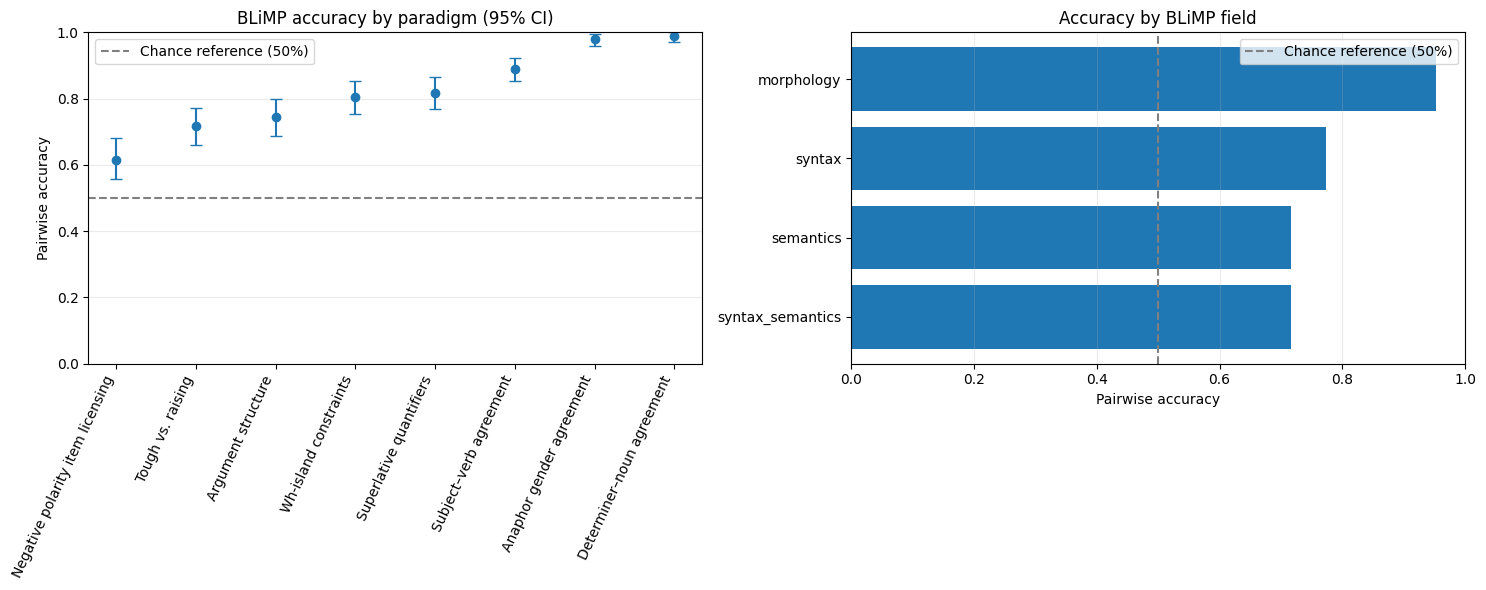

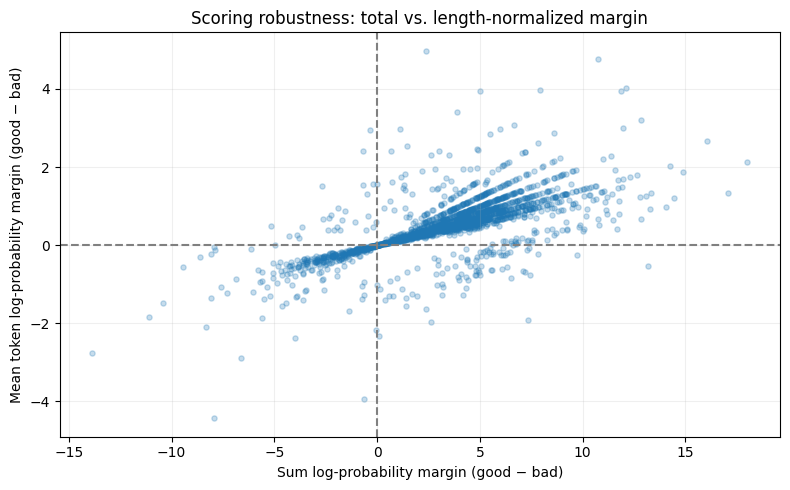

Saved: /kaggle/working/qwen3_blimp_accuracy.png /kaggle/working/qwen3_blimp_margin_comparison.png


In [9]:
plot_df=ci_df.sort_values("accuracy").reset_index(drop=True)
x=np.arange(len(plot_df)); y=plot_df["accuracy"].to_numpy()
lo=plot_df["ci95_low"].to_numpy(); hi=plot_df["ci95_high"].to_numpy()
fig,axes=plt.subplots(1,2,figsize=(15,6))
axes[0].errorbar(x,y,yerr=np.vstack([y-lo,hi-y]),fmt="o",capsize=4)
axes[0].axhline(.5,linestyle="--",color="gray",label="Chance reference (50%)")
axes[0].set_xticks(x); axes[0].set_xticklabels(plot_df["paradigm"],rotation=65,ha="right")
axes[0].set_ylim(0,1); axes[0].set_ylabel("Pairwise accuracy")
axes[0].set_title("BLiMP accuracy by paradigm (95% CI)"); axes[0].grid(axis="y",alpha=.25); axes[0].legend()
fs=field_summary.sort_values("sum_pairwise_accuracy")
axes[1].barh(fs["field"],fs["sum_pairwise_accuracy"])
axes[1].axvline(.5,linestyle="--",color="gray",label="Chance reference (50%)")
axes[1].set_xlim(0,1); axes[1].set_xlabel("Pairwise accuracy")
axes[1].set_title("Accuracy by BLiMP field"); axes[1].grid(axis="x",alpha=.25); axes[1].legend()
plt.tight_layout(); fig_path=OUT_DIR/"qwen3_blimp_accuracy.png"
plt.savefig(fig_path,dpi=180,bbox_inches="tight"); plt.show()
fig,ax=plt.subplots(figsize=(8,5))
ax.scatter(details_df["sum_margin_good_minus_bad"],details_df["mean_margin_good_minus_bad"],alpha=.25,s=14)
ax.axhline(0,linestyle="--",color="gray"); ax.axvline(0,linestyle="--",color="gray")
ax.set_xlabel("Sum log-probability margin (good − bad)"); ax.set_ylabel("Mean token log-probability margin (good − bad)")
ax.set_title("Scoring robustness: total vs. length-normalized margin"); ax.grid(alpha=.2)
plt.tight_layout(); margin_path=OUT_DIR/"qwen3_blimp_margin_comparison.png"
plt.savefig(margin_path,dpi=180,bbox_inches="tight"); plt.show()
print("Saved:",fig_path,margin_path)

## 10. Error analysis

In [10]:
errors=details_df[~details_df["sum_preferred_good"].astype(bool)].copy()
errors=errors.sort_values("sum_margin_good_minus_bad",ascending=True)
display(errors[["paradigm","field","linguistics_term","sentence_good","sentence_bad",
                "sum_margin_good_minus_bad","mean_margin_good_minus_bad"]].head(25))
error_summary=(details_df.assign(error=~details_df["sum_preferred_good"].astype(bool))
  .groupby(["paradigm","field"],dropna=False).agg(n_pairs=("error","size"),errors=("error","sum"),
  error_rate=("error","mean")).reset_index().sort_values("error_rate",ascending=False))
display(error_summary.round(4)); error_summary.to_csv(OUT_DIR/"qwen3_blimp_error_analysis.csv",index=False)

,paradigm,field,linguistics_term,sentence_good,sentence_bad,sum_margin_good_minus_bad,mean_margin_good_minus_bad
902,Argument structure,syntax,argument_structure,Rachel's girlfriend ascends.,Rachel's girlfriend dropped by.,-13.851273,-2.770255
1031,Tough vs. raising,syntax_semantics,control_raising,Kendra was irritating to reveal.,Kendra was unlikely to reveal.,-11.106968,-1.851161
234,Subject–verb agreement,morphology,subject_verb_agreement,Beth hasn't boycotted some association.,Beth haven't boycotted some association.,-10.436890,-1.490984
754,Argument structure,syntax,argument_structure,Valerie skates around.,Valerie complains about.,-9.456329,-0.561013
978,Argument structure,syntax,argument_structure,Rhonda should skate around.,Rhonda should examine.,-8.606880,-0.307340
98,Subject–verb agreement,morphology,subject_verb_agreement,Todd cleans many forks.,Todd clean many forks.,-8.337128,-2.084282
1137,Tough vs. raising,syntax_semantics,control_raising,Some glacier isn't hard work to drop by.,Some glacier isn't about to drop by.,-8.093346,-0.230118
1135,Tough vs. raising,syntax_semantics,control_raising,All pictures are enjoyable to lift.,All pictures are bound to lift.,-8.057423,-1.342904
887,Argument structure,syntax,argument_structure,Catherine skated around.,Catherine listened to.,-7.945116,-0.050853
837,Argument structure,syntax,argument_structure,Tamara exits.,Tamara cures.,-7.944597,-4.433259


,paradigm,field,n_pairs,errors,error_rate
3,Negative polarity item licensing,semantics,250,96,0.384
6,Tough vs. raising,syntax_semantics,250,71,0.284
1,Argument structure,syntax,250,64,0.256
7,Wh-island constraints,syntax,250,49,0.196
5,Superlative quantifiers,semantics,250,46,0.184
4,Subject–verb agreement,morphology,250,28,0.112
0,Anaphor gender agreement,morphology,250,5,0.020
2,Determiner–noun agreement,morphology,250,3,0.012
